In [45]:
import tskit
import pandas as pd
import numpy as np
from collections import Counter
from matplotlib import pyplot as plt
import scipy
import seaborn as sns
from matplotlib.patches import Patch

chromosomes = [16]

In [7]:
chromosome = 16
ts = tskit.load("/sietch_colab/jobste/Singer/Chr" + str(chromosome) + "/Chr" + str(chromosome) + "_NonHybrid_99.trees")
samples = pd.read_csv("/home/jobste/Data/Remapped/NonHybrid_samples.txt", header = None, names = ["ID"])

# %%
meta = pd.read_csv("/home/jobste/Data/TsinferMetaData_Vcf.txt")
meta.head()
allMeta = pd.read_csv("/home/jobste/Data/DataDescriptor_SampleMeta.csv")
allMeta.head()
meta.loc[:, "Country"] = [allMeta.Country[allMeta.Run == x].to_list()[0] for x in meta.ID]
# Add country as pop
sampleMeta = samples.merge(meta, how = "left", on = "ID")


complex_schema_pop = tskit.MetadataSchema({
    'codec': 'json',
    'additionalProperties': False,
    'properties': {'pop': {'description': 'Lineage',
                        'type': 'string'},
                'subpop': {'description': 'Subspecies',
                        'type': 'string'},
                'country': {'description': 'Country',
                        'type': 'string'}},
    'required': ['pop'],
    'type': 'object',
})

tables = ts.dump_tables()
tables.populations.metadata_schema = complex_schema_pop

# Add data to population table
popdata_column = [{"pop": pop, "subpop":subpop, "country": country } for pop,subpop,country in set(list(zip(sampleMeta.Pop, sampleMeta.SubPop, sampleMeta.Country)))]
encoded_popdata_column = [
    tables.populations.metadata_schema.validate_and_encode_row(r) for r in popdata_column
]
md, md_offset = tskit.pack_bytes(encoded_popdata_column)
tables.populations.set_columns(metadata=md, metadata_offset=md_offset)

popDict = {y: x for x,y in enumerate(set(list(zip(sampleMeta.Pop, sampleMeta.SubPop, sampleMeta.Country))))}
ind_nodes = list([x.id for x in ts.nodes() if x.time == 0.0])
ind_pops = [popDict[(sampleMeta.Pop.to_list()[x], sampleMeta.SubPop.to_list()[x], sampleMeta.Country.to_list()[x])] for x in ind_nodes]


indNodePop = tables.nodes.population
indNodePop[ind_nodes] = ind_pops
tables.nodes.population = indNodePop
ts_meta = tables.tree_sequence()
lineages = set([x.metadata["pop"] for x in ts_meta.populations()])
subspecies = set([x.metadata["subpop"] for x in ts_meta.populations()])
countries = set([x.metadata["country"] for x in ts_meta.populations()])

In [46]:
for chromosome in chromosomes:
    ts = tskit.load("/sietch_colab/jobste/Singer/Chr" + str(chromosome) + "/Chr" + str(chromosome) + "_NonHybrid_99.trees")
    samples = pd.read_csv("/home/jobste/Data/Remapped/NonHybrid_samples.txt", header = None, names = ["ID"])

    # %%
    meta = pd.read_csv("/home/jobste/Data/TsinferMetaData_Vcf.txt")
    meta.head()
    allMeta = pd.read_csv("/home/jobste/Data/DataDescriptor_SampleMeta.csv")
    allMeta.head()
    meta.loc[:, "Country"] = [allMeta.Country[allMeta.Run == x].to_list()[0] for x in meta.ID]
    # Add country as pop
    sampleMeta = samples.merge(meta, how = "left", on = "ID")


    complex_schema_pop = tskit.MetadataSchema({
        'codec': 'json',
        'additionalProperties': False,
        'properties': {'pop': {'description': 'Lineage',
                            'type': 'string'},
                    'subpop': {'description': 'Subspecies',
                            'type': 'string'},
                    'country': {'description': 'Country',
                            'type': 'string'}},
        'required': ['pop'],
        'type': 'object',
    })

    tables = ts.dump_tables()
    tables.populations.metadata_schema = complex_schema_pop

    # Add data to population table
    popdata_column = [{"pop": pop, "subpop":subpop, "country": country } for pop,subpop,country in set(list(zip(sampleMeta.Pop, sampleMeta.SubPop, sampleMeta.Country)))]
    encoded_popdata_column = [
        tables.populations.metadata_schema.validate_and_encode_row(r) for r in popdata_column
    ]
    md, md_offset = tskit.pack_bytes(encoded_popdata_column)
    tables.populations.set_columns(metadata=md, metadata_offset=md_offset)

    popDict = {y: x for x,y in enumerate(set(list(zip(sampleMeta.Pop, sampleMeta.SubPop, sampleMeta.Country))))}
    ind_nodes = list([x.id for x in ts.nodes() if x.time == 0.0])
    ind_pops = [popDict[(sampleMeta.Pop.to_list()[x], sampleMeta.SubPop.to_list()[x], sampleMeta.Country.to_list()[x])] for x in ind_nodes]


    indNodePop = tables.nodes.population
    indNodePop[ind_nodes] = ind_pops
    tables.nodes.population = indNodePop
    ts_meta = tables.tree_sequence()
    lineages = set([x.metadata["pop"] for x in ts_meta.populations()])
    subspecies = set([x.metadata["subpop"] for x in ts_meta.populations()])
    countries = set([x.metadata["country"] for x in ts_meta.populations()])

    nodes_by_ind = [[x] for x in ind_nodes]
    subspecies
    #GNN
    samples_listed_by_subsp = [
        [node for node,nodePop in zip(ind_nodes, ind_pops) if ts_meta.population(nodePop).metadata["subpop"] == pop] for pop in subspecies
    ]
    samples_listed_by_subsp = [x for x in samples_listed_by_subsp if len(x) != 0]

    samples_listed_by_lineage = [
        [node for node,nodePop in zip(ind_nodes, ind_pops) if ts_meta.population(nodePop).metadata["pop"] == pop] for pop in lineages
    ]



    gnn = ts_meta.genealogical_nearest_neighbours(ind_nodes, nodes_by_ind)
    cols = {nodes_by_ind[i][0]: gnn[:, i] for i in range(len(nodes_by_ind))}
    cols['pop'] = [ts_meta.population(ts_meta.node(u).population).metadata['pop'] for u in ind_nodes]
    cols['subpop'] = [ts_meta.population(ts_meta.node(u).population).metadata['subpop'] for u in ind_nodes]
    cols['country'] = [ts_meta.population(ts_meta.node(u).population).metadata['country'] for u in ind_nodes]
    cols['individual'] = ind_nodes
    df = pd.DataFrame(cols)
    df.to_csv("Gnn_Chromosome_"+ str(chromosome) + ".csv")

In [2]:
genome = {
    "assembly_accession": "GCA_003254395.2",
    "assembly_name": "Amel_HAv3.1",
    "chromosomes": {
        "CM009931.2": {"length": 27754200, "synonyms": ["NC_037638.1"]},
        "CM009932.2": {"length": 16089512, "synonyms": ["NC_037639.1"]},
        "CM009933.2": {"length": 13619445, "synonyms": ["NC_037640.1"]},
        "CM009934.2": {"length": 13404451, "synonyms": ["NC_037641.1"]},
        "CM009935.2": {"length": 13896941, "synonyms": ["NC_037642.1"]},
        "CM009936.2": {"length": 17789102, "synonyms": ["NC_037643.1"]},
        "CM009937.2": {"length": 14198698, "synonyms": ["NC_037644.1"]},
        "CM009938.2": {"length": 12717210, "synonyms": ["NC_037645.1"]},
        "CM009939.2": {"length": 12354651, "synonyms": ["NC_037646.1"]},
        "CM009940.2": {"length": 12360052, "synonyms": ["NC_037647.1"]},
        "CM009941.2": {"length": 16352600, "synonyms": ["NC_037648.1"]},
        "CM009942.2": {"length": 11514234, "synonyms": ["NC_037649.1"]},
        "CM009943.2": {"length": 11279722, "synonyms": ["NC_037650.1"]},
        "CM009944.2": {"length": 10670842, "synonyms": ["NC_037651.1"]},
        "CM009945.2": {"length": 9534514, "synonyms": ["NC_037652.1"]},
        "CM009946.2": {"length": 7238532, "synonyms": ["NC_037653.1"]},
        "CM009947.2": {"length": 16343, "synonyms": ["NC_001566.1", "MT"]},
    },
}

chromosomesCM = genome['chromosomes']
chrLengths = [value['length'] for value in chromosomesCM.values()]
chrPer = [x / sum(chrLengths) for x in chrLengths]


In [8]:
nInd = ts_meta.num_samples
for chromosome in chromosomes:
    chrGnn = pd.read_csv("Gnn_Chromosome_"+ str(chromosome) + ".csv", index_col = None)
    if chromosome == chromosomes[0]:
        combinedGnn = chrGnn.iloc[:, 1:(nInd+1)]
        info = chrGnn.iloc[:, (nInd+1):]
    else:
        combinedGnn = combinedGnn + chrGnn.iloc[:, 1:(nInd+1)] * chrPer[chromosome - 1]


In [51]:
df = pd.concat([combinedGnn, info], axis=1)
#df = chrGnn
dfCopy = df.copy()
df.drop(['pop', 'subpop', 'country'], axis=1, inplace=True)


In [43]:
def lineages_colours():
    return {
        "A": "#feb72d", 
        "O": "#a8db34",
        "M": "#228c8d", 
        "C": "#802694"
    }

def subspecies_colours():
    return {
        "Capensis": "#f7e225",
        "Scutellata": "#feb72d",
        "Unicolor": "#f07f4f",
        "Ligustica": "#310597",
        "Carnica": "#ad2793",
        "Mellifera": "#228c8d",
        "Iberiensis": "#87e5e6",
        "Caucasia": "#a8db34",
        "Buckfast": "#9298a1"
    }



def get_subspecies_colours(dataframe):
    # TODO add option to give shades for the different pops.
    lineage_colours = lineages_colours()
    subspecies_colour_map = {}
    for lineage, subspecie in zip(dataframe['pop'], dataframe['subpop']):
        subspecies_colour_map[subspecie] = lineage_colours[lineage]
    return subspecies_colour_map


def get_ind_colours_lineages(dataframe):
    # TODO add option to give shades for the different pops.
    lineage_colour = lineages_colours()
    ind_colour_map = {}
    for lineage, ind in zip(dataframe['pop'], dataframe['individual']):
        ind_colour_map[ind] = lineage_colour[lineage]
    return ind_colour_map

def get_ind_colours_subspecies(dataframe):
    # TODO add option to give shades for the different pops.
    subspecie_colours = subspecies_colours()
    ind_colour_map = {}
    for subspecie, ind in zip(dataframe['subpop'], dataframe['individual']):
        ind_colour_map[ind] = subspecie_colours[subspecie]
    return ind_colour_map

dark_palette = sns.color_palette("dark", int(len(countries)/2))
light_palette = sns.color_palette("pastel", int(len(countries)/2))

# Combine dark and light colors alternately to create high-contrast palette
high_contrast_palette = []
for dark_color, light_color in zip(dark_palette, light_palette):
    high_contrast_palette.append(dark_color)
    high_contrast_palette.append(light_color)
country_colours = dict(zip(countries, high_contrast_palette))

def get_ind_colours_countries(dataframe, country_colours):
    # TODO add option to give shades for the different pops.
    ind_colour_map = {}
    for country, ind in zip(dataframe.country, dataframe.individual):
        ind_colour_map[ind] = country_colours[country]
    return ind_colour_map

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


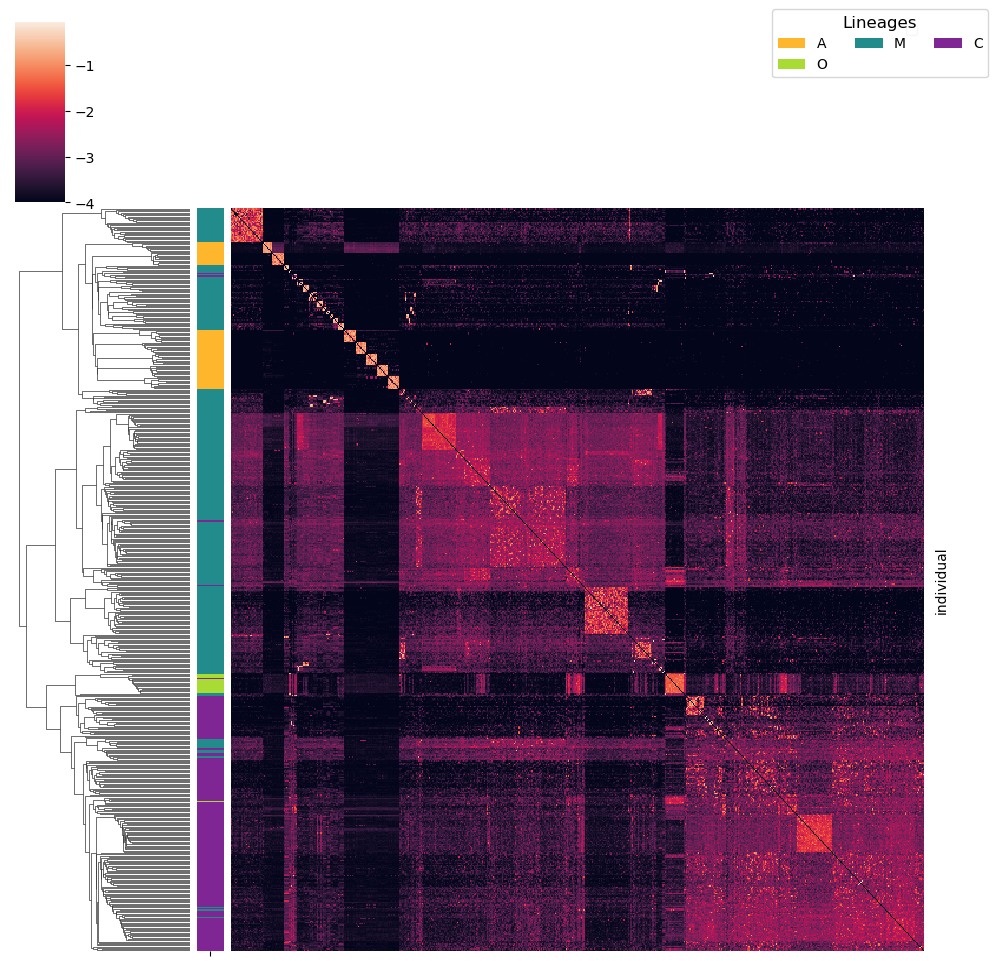

In [59]:
figsize = (10, 10)
dfg = df.groupby("individual").mean()

# Z-score normalization using np.log1p to avoid log(0)
dfg = dfg.apply(lambda x: np.log10(x+0.0001))
row_linkage = scipy.cluster.hierarchy.linkage(dfg, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = [str(x) for x in dfg.index.values[order]]

# Ensure the columns are sorted according to clustering
#dfg = dfg.iloc[order]

# Get the colors for each individual
row_colors = pd.Series(get_ind_colours_lineages(dfCopy), index=dfg.index)

# Plot the clustermap
cg = sns.clustermap(
    dfg[x_pop], row_linkage=row_linkage, col_cluster=False,
    figsize=(10, 10), rasterized=True, row_colors=row_colors)

cg.ax_col_dendrogram.legend(ncol=5)
cg.ax_heatmap.set_yticks([])
cg.ax_heatmap.set_xticks([])




#handles = [Patch(facecolor=country_colours[name]) for name in countries]
#plt.legend(handles, country_colours, title='Countries',
#           bbox_to_anchor=(1, 1), bbox_transform=plt.gcf().transFigure, loc='upper right',
#           prop={'size': 10}, ncol=3, title_fontsize=12)

handles = [Patch(facecolor=lineages_colours()[name]) for name in lineages_colours().keys()]
plt.legend(handles, lineages_colours(), title='Lineages',
           bbox_to_anchor=(1, 1), bbox_transform=plt.gcf().transFigure, loc='upper right',
           prop={'size': 10}, ncol=3, title_fontsize=12)

plt.show()


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


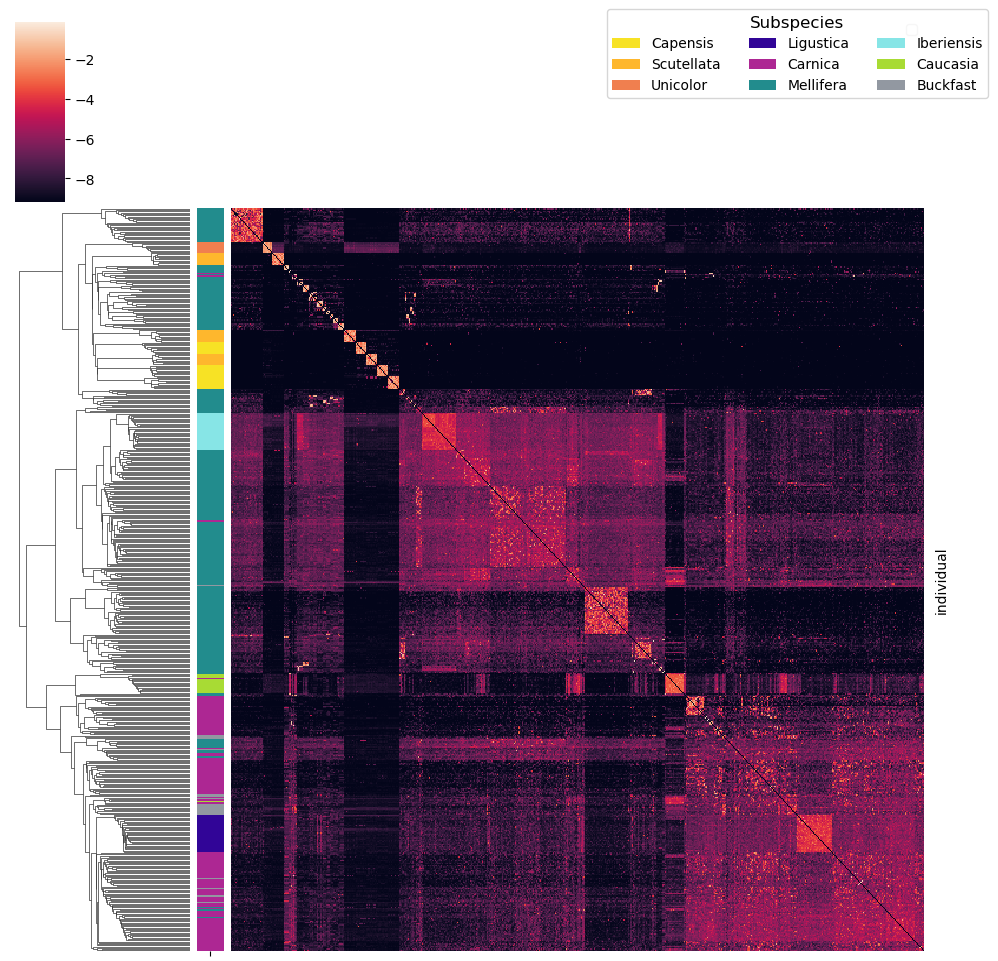

In [60]:
figsize = (10, 10)
dfg = df.groupby("individual").mean()
# Zscore normalise
for col in list(dfg):
    dfg[col] = np.log(dfg[col] + 0.0001)
row_linkage = scipy.cluster.hierarchy.linkage(dfg, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = [str(x) for x in dfg.index.values[order]]


cg = sns.clustermap(
    dfg[x_pop], row_linkage=row_linkage, col_cluster=False, # dfg[x_pop] dfgOrder[list(dfgOrder.individual)]
    figsize=figsize, rasterized=True, row_colors = pd.Series(get_ind_colours_subspecies(dfCopy)))


cg.ax_col_dendrogram.legend(ncol=5)
cg.ax_heatmap.set_yticks([])
cg.ax_heatmap.set_xticks([])



handles = [Patch(facecolor=subspecies_colours()[name]) for name in subspecies_colours().keys()]
plt.legend(handles, subspecies_colours(), title='Subspecies',
           bbox_to_anchor=(1, 1), bbox_transform=plt.gcf().transFigure, loc='upper right',
           prop={'size': 10}, ncol=3, title_fontsize=12)

plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


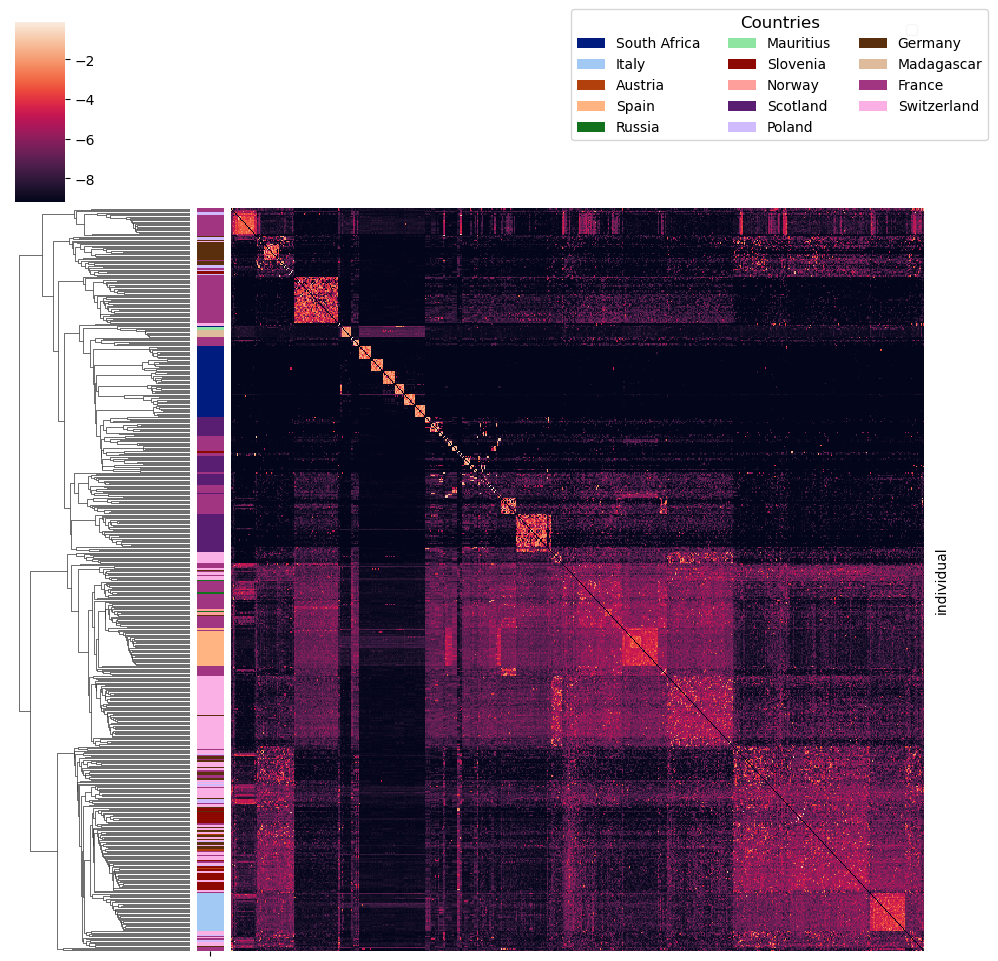

In [38]:
figsize = (10, 10)
dfg = df.groupby("individual").mean()
# Zscore normalise
for col in list(dfg):
    dfg[col] = np.log(dfg[col] + 0.0001)
row_linkage = scipy.cluster.hierarchy.linkage(dfg, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = dfg.index.values[order]

cg = sns.clustermap(
    dfg[x_pop], row_linkage=row_linkage, col_cluster=False, # dfg[x_pop] dfgOrder[list(dfgOrder.individual)]
    figsize=figsize, rasterized=True, row_colors = pd.Series(get_ind_colours_countries(dfCopy, country_colours)))


cg.ax_col_dendrogram.legend(ncol=5)
cg.ax_heatmap.set_yticks([])
cg.ax_heatmap.set_xticks([])




handles = [Patch(facecolor=country_colours[name]) for name in country_colours.keys()]
plt.legend(handles, country_colours, title='Countries',
           bbox_to_anchor=(1, 1), bbox_transform=plt.gcf().transFigure, loc='upper right',
           prop={'size': 10}, ncol=3, title_fontsize=12)


plt.show()

In [1]:
figsize = (10, 10)
dfg = df.groupby("individual").mean()
# Zscore normalise
for col in list(dfg):
    dfg[col] = np.log(dfg[col] + 0.0001)
row_linkage = scipy.cluster.hierarchy.linkage(dfg, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = dfg.index.values[order]

cg = sns.clustermap(
    dfg[x_pop], row_linkage=row_linkage, col_cluster=False, # dfg[x_pop] dfgOrder[list(dfgOrder.individual)]
    figsize=figsize, rasterized=True, row_colors = pd.Series(get_ind_colours_countries(dfCopy, country_colours)))


cg.ax_col_dendrogram.legend(ncol=5)
cg.ax_heatmap.set_yticks([])
cg.ax_heatmap.set_xticks([])




handles = [Patch(facecolor=country_colours[name]) for name in country_colours.keys()]
plt.legend(handles, country_colours, title='Countries',
           bbox_to_anchor=(1, 1), bbox_transform=plt.gcf().transFigure, loc='upper right',
           prop={'size': 10}, ncol=3, title_fontsize=12)


plt.show()

NameError: name 'df' is not defined

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


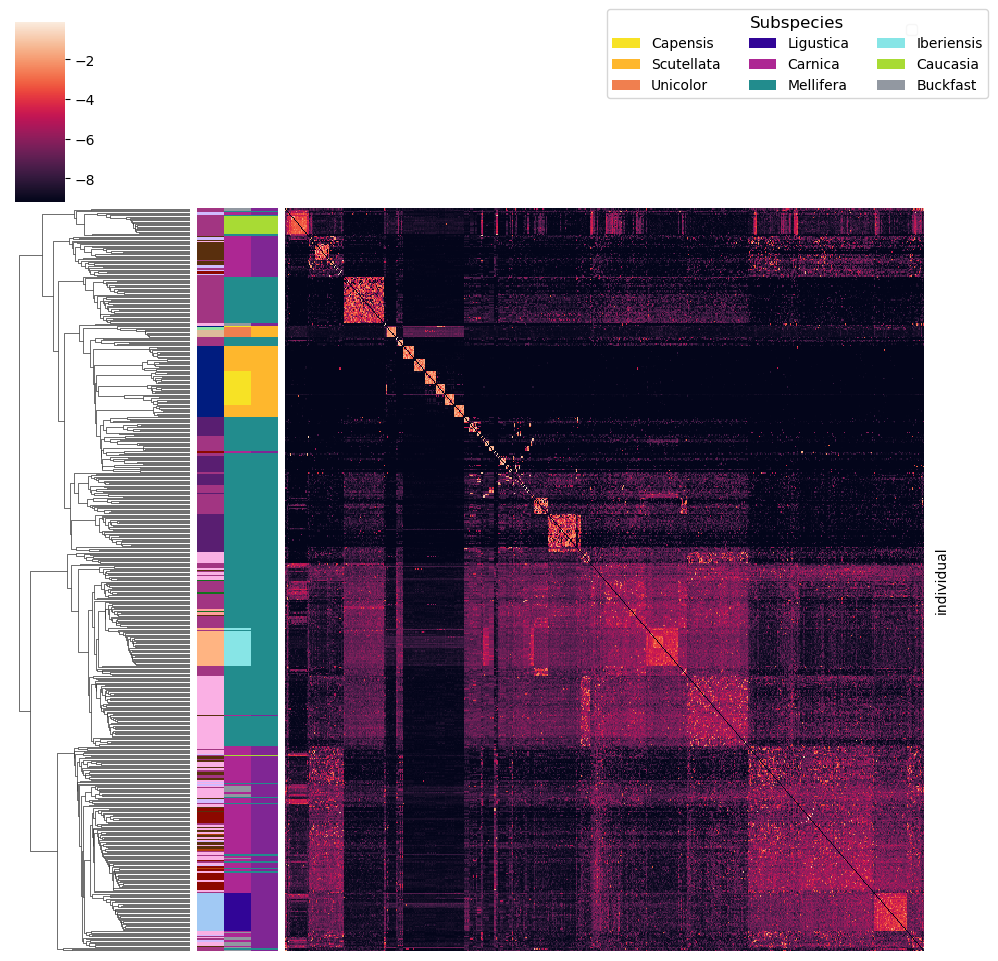

In [57]:
figsize = (10, 10)
dfg = df.groupby("individual").mean()
# Zscore normalise
for col in list(dfg):
    dfg[col] = np.log(dfg[col] + 0.0001)
row_linkage = scipy.cluster.hierarchy.linkage(dfg, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = dfg.index.values[order]


cg = sns.clustermap(
    dfg[x_pop], row_linkage=row_linkage, col_cluster=False, # dfg[x_pop] dfgOrder[list(dfgOrder.individual)]
    figsize=figsize, rasterized=True, row_colors = [pd.Series(get_ind_colours_countries(dfCopy, country_colours)), pd.Series(get_ind_colours_subspecies(dfCopy)), pd.Series(get_ind_colours_lineages(dfCopy))])


cg.ax_col_dendrogram.legend(ncol=5)
cg.ax_heatmap.set_yticks([])
cg.ax_heatmap.set_xticks([])



handles = [Patch(facecolor=subspecies_colours()[name]) for name in subspecies_colours().keys()]
plt.legend(handles, subspecies_colours(), title='Subspecies',
           bbox_to_anchor=(1, 1), bbox_transform=plt.gcf().transFigure, loc='upper right',
           prop={'size': 10}, ncol=3, title_fontsize=12)

plt.show()

In [28]:
country_colours

{'South Africa': (0.0, 0.10980392156862745, 0.4980392156862745),
 'Italy': (0.6313725490196078, 0.788235294117647, 0.9568627450980393),
 'Austria': (0.6941176470588235, 0.25098039215686274, 0.050980392156862744),
 'Spain': (1.0, 0.7058823529411765, 0.5098039215686274),
 'Russia': (0.07058823529411765, 0.44313725490196076, 0.10980392156862745),
 'Mauritius': (0.5529411764705883, 0.8980392156862745, 0.6313725490196078),
 'Slovenia': (0.5490196078431373, 0.03137254901960784, 0.0),
 'Norway': (1.0, 0.6235294117647059, 0.6078431372549019),
 'Scotland': (0.34901960784313724, 0.11764705882352941, 0.44313725490196076),
 'Poland': (0.8156862745098039, 0.7333333333333333, 1.0),
 'Germany': (0.34901960784313724, 0.1843137254901961, 0.050980392156862744),
 'Madagascar': (0.8705882352941177, 0.7333333333333333, 0.6078431372549019),
 'France': (0.6352941176470588, 0.20784313725490197, 0.5098039215686274),
 'Switzerland': (0.9803921568627451, 0.6901960784313725, 0.8941176470588236)}